# B0: Reproducing the DenseNet121 baseline of Ali et al. (2024) on MSLD v2.0

This notebook reproduces the ImageNet-pretrained DenseNet121 from Ali et al., "A web-based mpox skin lesion detection system using state-of-the-art deep learning models considering racial diversity", *Biomedical Signal Processing and Control* 98 (2024) 106742. The target is Table 2 of the paper: 81.70 ± 5.39% accuracy, 0.83 ± 0.04 precision, 0.79 ± 0.06 sensitivity and 0.80 ± 0.06 F1 over five patient-independent folds. I count the reproduction as successful if our mean accuracy is within one of the paper's standard deviations.

What comes from the paper:

1. Model (Section 5.3): 224×224×3 input, all layers trainable, the DenseNet121 output flattened and passed to fully connected layers of 4096, 1072 and 256 nodes with dropout of 0.3, 0.2 and 0.15, then a 6-node softmax layer.
2. Training (Table 3): batch size 16, learning rate 0.00001, 100 epochs, Adam, categorical cross-entropy. The paper says these were picked by validation performance and then used for every model.
3. Protocol (Section 5.1): five folds split about 70:20:10 with no patient in two splits, and only the training images augmented.
4. Augmentation (Section 4.3): rotation, translation, reflection, shear, hue, saturation, contrast and brightness jitter, noise and scaling, which made the training set about 14 times larger.

What the paper leaves open, and what I chose:

1. Which weights get tested. Nothing is said about early stopping or checkpoints, so the main result uses the model after epoch 100. I also report the weights from the epoch with the best validation accuracy as a second result, since that only uses validation data.
2. What one epoch means. The paper's epochs ran over the 14x augmented training set. I augment on the fly instead, so I repeat each training image `REPEAT = 14` times per epoch with fresh random augmentation. That keeps 100 of our epochs close to 100 of theirs in number of optimizer steps (about 465 steps per epoch).
3. Activation in the hidden layers. Not named, so I assume ReLU, in the order Dense, ReLU, Dropout.
4. Augmentation ranges. Not given, so I picked moderate values.
5. Keras defaults. The paper used Keras, so I copy its defaults where PyTorch differs: Glorot-uniform initialisation for the dense layers, Adam epsilon of 1e-7, BatchNorm momentum of 0.99, and a ReLU after the DenseNet features.

The validation set is not augmented. The test set is only scored after a fold has finished training.

To run it on Kaggle: add the dataset `joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20` to the notebook (Add Input), turn on a GPU and turn on Internet (needed once, to download the ImageNet weights). The notebook finds the `FOLDS` folder of the original images by itself. It holds `fold1` to `fold5`, each with `Train`, `Valid` and `Test` folders and one subfolder per class, and these folders define the five patient-independent splits (they match the official `datalog.xlsx`). Every image also exists as a byte-identical copy with an extra `_1` in its name (for example `CHP_08_01.jpg` and `CHP_08_01_1.jpg`), so the notebook keeps only the originals; the dataset then has 755 images, as in the paper. First set `QUICK = True` in section 2 and run everything once to check the pipeline, then set it back to `False`. 100 epochs is a long run, roughly an hour or more per fold. The notebook saves a checkpoint every 10 epochs and continues from it if the checkpoint files are still in the output folder. To continue after a session has ended, add the earlier output as an input and set `RESTORE_FROM` (section 2). Curves and test metrics go to Weights & Biases if a `WANDB_API_KEY` secret is set.


## 1. Imports

In [1]:
# All of these come preinstalled on Colab and Kaggle
import os, time, random, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu128


## 2. Settings

In [2]:
# Settings from Table 3 of Ali et al. (2024)
IMG = 224          # input size
BATCH = 16         # batch size
LR = 1e-5          # learning rate
EPOCHS = 100      # number of epochs
NUM_CLASSES = 6

# Settings I chose, because the paper does not give them
REPEAT = 14        # passes over the training images per epoch (matches the paper's 14x augmented set)
USE_AMP = True     # mixed precision on GPU, which is faster and uses less memory
CKPT_EVERY = 10    # save a resume checkpoint every this many epochs
SEED = 42
RUN_NAME = "b0_100ep"   # names the output folder and the W&B runs; use a new name for each new experiment
NUM_WORKERS = 2   # data-loading worker processes
FOLDS = [1, 2, 3, 4, 5]

# Quick check of the whole pipeline before the real run: 1 fold, 2 short epochs
QUICK = False
if QUICK:
    EPOCHS, REPEAT, FOLDS = 2, 1, [1]
    RUN_NAME += "_quick"   # keeps the test run apart from the real one

# Where results go (Kaggle keeps /kaggle/working as the notebook output)
OUT = Path(f"/kaggle/working/{RUN_NAME}")
OUT.mkdir(parents=True, exist_ok=True)
SAVE_WEIGHTS = True   # each saved model is about 870 MB, two are kept per fold (final and best-val); we need them later for the attacks

USE_WANDB = True                      # log curves and test metrics to Weights & Biases (needs a WANDB_API_KEY Kaggle secret)
WANDB_PROJECT = "mpox-b0-densenet121"
# To continue an earlier run: add that notebook version's output as an input (Add Input -> Notebook Output)
# and put the path of its folder here, e.g. "/kaggle/input/<notebook-output>". Leave None for a fresh run.
RESTORE_FROM = None

# Table 2 of the paper (ImageNet weights, DenseNet121), for the comparison at the end
PAPER = {"acc": (81.70, 5.39), "precision": (0.83, 0.04), "sensitivity": (0.79, 0.06), "f1": (0.80, 0.06)}

## 2b. Weights & Biases and restoring an earlier run

W&B logs the training curves and the test metrics of each fold; the model files stay in the output folder. Each fold is one W&B run with a fixed id, so a fold that is resumed after an interruption continues the same run. If the W&B login fails, logging is switched off and training carries on.

If `RESTORE_FROM` is set, finished folds (`fold{k}.json`) and the resume files of unfinished folds are copied from that folder into the output folder, so the next cell that trains skips what is done and resumes the rest.

In [3]:
import shutil

if USE_WANDB:
    try:
        import wandb
        from kaggle_secrets import UserSecretsClient
        wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
    except Exception as e:
        print("W&B off:", e)
        USE_WANDB = False

if RESTORE_FROM:
    found = {}
    for dp, _, fs in os.walk(RESTORE_FROM, followlinks=True):
        for name in fs:
            found.setdefault(name, Path(dp) / name)
    assert found, f"No files found under {RESTORE_FROM}"
    for k in range(1, 6):
        done = f"fold{k}.json"
        need = [done] if done in found else [f"b0_fold{k}_last.pt", f"b0_fold{k}_bestval.pt"]
        if not all(n in found for n in need):
            continue
        for name in need:
            if not (OUT / name).exists():
                shutil.copy2(found[name], OUT / name)
                print("restored", name)
print("OUT:", OUT, "| W&B:", USE_WANDB)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ajimoh (ajimoh-carnegie-mellon-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


OUT: /kaggle/working/b0_100ep | W&B: True


## 3. Point to the dataset

The notebook looks for the `FOLDS` folder of the original images under `/kaggle/input`. It uses the original images, not the augmented ones, because it augments on the fly.

In [4]:

def find_folds_root():
    for dirpath, dirnames, _ in os.walk("/kaggle/input", followlinks=True):
        if os.path.basename(dirpath) == "FOLDS" and "fold1" in dirnames:   # FOLDS_AUG (augmented) does not match
            return Path(dirpath)
    return None

DATA_ROOT = find_folds_root()
assert DATA_ROOT is not None, "Could not find the FOLDS folder. Add the MSLD v2.0 dataset to the notebook (Add Input)."
print("Using:", DATA_ROOT)


Using: /kaggle/input/datasets/joydippaul/mpox-skin-lesion-dataset-version-20-msld-v20/Original Images/Original Images/FOLDS


## 4. Read the folds

Image names follow the pattern `MKP_17_01`: disease code, patient number, image number. The class comes from the folder, and the patient comes from the file name. Each image also has a byte-identical copy named like `MKP_17_01_1`; I keep only the three-part names, otherwise the training set would double in size and every validation and test image would be counted twice.

For every fold I check that no image and no patient appears in two splits, and that the disease code in each file name agrees with its class folder.

In [5]:
CLASSES = ["Chickenpox", "Cowpox", "HFMD", "Healthy", "Measles", "Monkeypox"]   # folder names, alphabetical like Keras
CLS_ID = {c: i for i, c in enumerate(CLASSES)}
CODES = {"CHP": "Chickenpox", "CWP": "Cowpox", "HFMD": "HFMD", "HEALTHY": "Healthy", "MSL": "Measles", "MKP": "Monkeypox"}
EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
SPLITS = {"train": "Train", "val": "Valid", "test": "Test"}

def is_original(stem):
    # "MKP_17_01" is an original; "MKP_17_01_1" is a byte-identical copy that we skip
    return len(stem.split("_")) == 3

def patient_of(stem):
    code, pid = stem.split("_")[:2]
    return f"{code.upper()}_{pid}"

def read_fold(k):
    data = {}
    for key, folder in SPLITS.items():
        items = []
        for c in CLASSES:
            for p in sorted((DATA_ROOT / f"fold{k}" / folder / c).iterdir()):
                if p.suffix.lower() in EXTS and is_original(p.stem):
                    assert CODES[p.stem.split("_")[0].upper()] == c, f"{p} sits in the wrong class folder"
                    items.append((p, CLS_ID[c]))
        data[key] = items
    return data

def check_fold(k, data):
    names = {key: {p.stem.lower() for p, _ in items} for key, items in data.items()}
    pats = {key: {patient_of(p.stem) for p, _ in items} for key, items in data.items()}
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert not names[a] & names[b], f"Fold {k}: images shared between {a} and {b}"
        assert not pats[a] & pats[b], f"Fold {k}: patients shared between {a} and {b}"
    assert sum(len(v) for v in data.values()) == 755, f"Fold {k}: expected 755 original images"

fold_data, rows = {}, []
for k in FOLDS:
    fold_data[k] = read_fold(k)
    check_fold(k, fold_data[k])
    for key, items in fold_data[k].items():
        counts = np.bincount([y for _, y in items], minlength=NUM_CLASSES)
        rows.append({"fold": k, "split": key, "total": len(items), **dict(zip(CLASSES, counts))})

print("All folds passed the leakage and label checks.")
pd.DataFrame(rows)

All folds passed the leakage and label checks.


,fold,split,total,Chickenpox,Cowpox,HFMD,Healthy,Measles,Monkeypox
0,1,train,537,50,49,116,83,37,202
1,1,val,144,16,10,29,22,12,55
2,1,test,74,9,7,16,9,6,27
3,2,train,509,51,47,109,80,40,182
4,2,val,164,13,15,32,23,10,71
5,2,test,82,11,4,20,11,5,31
6,3,train,538,51,47,114,75,36,215
7,3,val,153,18,15,31,28,14,47
8,3,test,64,6,4,16,11,5,22
9,4,train,524,52,44,115,83,36,194


## 5. Data loading and augmentation

The training transforms follow the list in Section 4.3 of the paper: rotation, translation, reflection, shear, hue, saturation, contrast and brightness jitter, noise and scaling. As in Section 5.1, only the training images are augmented. Validation and test images are only resized and normalised. Normalisation uses the ImageNet mean and standard deviation, which is also what Keras does for DenseNet121.

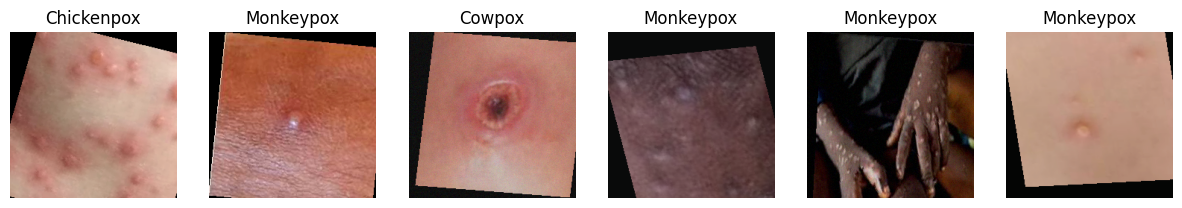

In [6]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class AddNoise:
    # Small Gaussian noise, applied to half of the images
    def __init__(self, std=0.02, p=0.5):
        self.std, self.p = std, p
    def __call__(self, x):
        if random.random() < self.p:
            x = (x + torch.randn_like(x) * self.std).clamp(0, 1)
        return x

train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=20, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    AddNoise(),
    transforms.Normalize(MEAN, STD),
])

test_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class SkinData(Dataset):
    def __init__(self, items, tf, repeat=1):
        self.items = items * repeat   # repeat the list so one epoch sees each image `repeat` times
        self.tf = tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        img = Image.open(path).convert("RGB")
        return self.tf(img), y

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loaders(k):
    data = fold_data[k]
    g = torch.Generator().manual_seed(SEED + k)
    # shuffle=True draws mini-batches without replacement, as in the paper
    train_dl = DataLoader(SkinData(data["train"], train_tf, REPEAT), batch_size=BATCH, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, worker_init_fn=seed_worker, generator=g)
    val_dl = DataLoader(SkinData(data["val"], test_tf), batch_size=32, num_workers=NUM_WORKERS, pin_memory=True)
    test_dl = DataLoader(SkinData(data["test"], test_tf), batch_size=32, num_workers=NUM_WORKERS, pin_memory=True)
    return train_dl, val_dl, test_dl

# Look at a few augmented training images as a sanity check
x, y = next(iter(make_loaders(FOLDS[0])[0]))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, img, lab in zip(axes, x[:6], y[:6]):
    img = img.permute(1, 2, 0).numpy() * STD + MEAN
    ax.imshow(img.clip(0, 1)); ax.set_title(CLASSES[int(lab)]); ax.axis("off")
plt.show()

## 6. The model

DenseNet121 gives a 1024×7×7 feature map. It is flattened to 50,176 values and passed through the paper's three dense blocks. This head has about 210 million parameters, around 30 times the backbone, so I print the count to confirm it matches the 217,147,062 from our proposal.

In [7]:
class PaperNet(nn.Module):
    def __init__(self, n_cls=NUM_CLASSES):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.backbone = base.features            # output shape: 1024 x 7 x 7
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024 * 7 * 7, 4096), nn.ReLU(), nn.Dropout(0.30),
            nn.Linear(4096, 1072), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(1072, 256), nn.ReLU(), nn.Dropout(0.15),
            nn.Linear(256, n_cls),                # softmax is applied inside the loss
        )
        # Keras starts dense layers with Glorot-uniform weights and zero bias
        for m in self.head:
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)
        # Keras BatchNorm uses momentum 0.99, which is 0.01 in PyTorch's convention
        for m in self.backbone.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.momentum = 0.01

    def forward(self, x):
        # Keras DenseNet121 ends with BatchNorm + ReLU; torchvision's features stop before the ReLU
        x = F.relu(self.backbone(x))
        return self.head(x)

tmp = PaperNet()
n_back = sum(p.numel() for p in tmp.backbone.parameters())
n_head = sum(p.numel() for p in tmp.head.parameters())
print(f"Backbone: {n_back:,}   Head: {n_head:,}   Total: {n_back + n_head:,}")
assert n_back + n_head == 217_147_062, "Parameter count does not match the proposal"
del tmp

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 140MB/s]


Backbone: 6,953,856   Head: 210,193,206   Total: 217,147,062


## 7. Training and evaluation functions

`run_epoch` handles both training and evaluation. `train_fold` trains one fold for the full 100 epochs and tracks validation accuracy after every epoch. When training ends it scores the test set twice: first with the final model (the main result), then with the weights from the best validation epoch (the second result).

A resume checkpoint is saved every `CKPT_EVERY` epochs and deleted once the fold is done. Finished folds are saved to `OUT/fold{k}.json` and skipped if you run the notebook again.

In [8]:
def run_epoch(model, loader, opt=None, scaler=None):
    train = opt is not None
    model.train(train)
    loss_sum, preds, labels = 0.0, [], []
    use_amp = USE_AMP and device.type == "cuda"
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = F.cross_entropy(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
            loss_sum += loss.item() * len(y)
            preds.append(out.argmax(1).cpu())
            labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return loss_sum / len(labels), float((preds == labels).mean()), preds, labels

def scores(y, p):
    # Macro-averaged precision, sensitivity (recall) and F1, plus mpox sensitivity
    prec, rec, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    _, rec_each, _, _ = precision_recall_fscore_support(y, p, labels=range(NUM_CLASSES), zero_division=0)
    return {"acc": float(100 * (y == p).mean()), "precision": float(prec), "sensitivity": float(rec),
            "f1": float(f1), "mpox_sens": float(rec_each[CLS_ID["Monkeypox"]])}

def train_fold(k):
    set_seed(SEED + k)
    train_dl, val_dl, test_dl = make_loaders(k)
    model = PaperNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, eps=1e-7)   # eps matches Keras
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP and device.type == "cuda")

    last_path = OUT / f"b0_fold{k}_last.pt"       # resume checkpoint
    best_path = OUT / f"b0_fold{k}_bestval.pt"    # weights from the best validation epoch
    hist, start = [], 1
    best = {"acc": -1.0, "loss": float("inf"), "epoch": 0}

    if last_path.exists():
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        hist, best, start = ck["hist"], ck["best"], ck["epoch"] + 1
        print(f"Fold {k}: resuming from epoch {start}")

    if USE_WANDB:
        wandb.finish()   # no-op unless a run is still open
        wandb.init(project=WANDB_PROJECT, id=f"{RUN_NAME}-fold{k}", name=f"{RUN_NAME}-fold{k}", resume="allow",
                   config={"fold": k, "epochs": EPOCHS, "batch": BATCH, "lr": LR, "repeat": REPEAT, "seed": SEED + k})
        wandb.define_metric("epoch"); wandb.define_metric("*", step_metric="epoch")
    print(f"Fold {k}: {len(train_dl.dataset)} training samples per epoch, {len(train_dl)} steps")
    for ep in range(start, EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_acc, _, _ = run_epoch(model, train_dl, opt, scaler)
        va_loss, va_acc, _, _ = run_epoch(model, val_dl)
        hist.append({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                     "val_loss": va_loss, "val_acc": va_acc})

        # Better = higher val accuracy, or the same accuracy with lower val loss
        mark = ""
        if va_acc > best["acc"] or (va_acc == best["acc"] and va_loss < best["loss"]):
            best = {"acc": va_acc, "loss": va_loss, "epoch": ep}
            torch.save(model.state_dict(), best_path)
            mark = "*"
        print(f"  ep {ep:3d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - t0:.0f}s {mark}")
        if USE_WANDB:
            wandb.log({"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc, "val_loss": va_loss, "val_acc": va_acc})

        if ep % CKPT_EVERY == 0 and ep < EPOCHS:
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                        "epoch": ep, "hist": hist, "best": best}, last_path)

    # Main result: the model after the last epoch
    _, _, p_final, y = run_epoch(model, test_dl)
    final = scores(y, p_final)
    if SAVE_WEIGHTS:
        torch.save(model.state_dict(), OUT / f"b0_fold{k}_final.pt")

    # Second result: the weights from the best validation epoch
    model.load_state_dict(torch.load(best_path, map_location=device))
    _, _, p_best, _ = run_epoch(model, test_dl)
    bestval = scores(y, p_best)

    print(f"Fold {k}: final model {final['acc']:.2f}% | best-val model (epoch {best['epoch']}) {bestval['acc']:.2f}%")
    with open(OUT / f"fold{k}.json", "w") as f:
        json.dump({"final": final, "bestval": bestval, "best_epoch": best["epoch"], "hist": hist,
                   "labels": y.tolist(), "preds_final": p_final.tolist(), "preds_bestval": p_best.tolist()}, f)

    if USE_WANDB:
        wandb.run.summary.update({**{f"test_final_{m}": v for m, v in final.items()},
                                  **{f"test_bestval_{m}": v for m, v in bestval.items()}, "best_epoch": best["epoch"]})
        wandb.finish()

    # Tidy up the large files we no longer need
    last_path.unlink(missing_ok=True)
    if not SAVE_WEIGHTS:
        best_path.unlink(missing_ok=True)
    del model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()

## 8. Train all five folds

In [9]:
for k in FOLDS:
    if (OUT / f"fold{k}.json").exists() and not QUICK:
        print(f"Fold {k} already done, skipping")
        continue
    train_fold(k)

wandb: setting up run b0_100ep-fold1
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261015_125040-b0_100ep-fold1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run b0_100ep-fold1
wandb: ⭐️ View project at https://wandb.ai/ajimoh-carnegie-mellon-university/mpox-b0-densenet121
wandb: 🚀 View run at https://wandb.ai/ajimoh-carnegie-mellon-university/mpox-b0-densenet121/runs/b0_100ep-fold1


Fold 1: 7518 training samples per epoch, 470 steps
  ep   1 | train loss 1.100 acc 0.615 | val loss 0.924 acc 0.681 | 85s *
  ep   2 | train loss 0.544 acc 0.798 | val loss 0.796 acc 0.757 | 84s *
  ep   3 | train loss 0.352 acc 0.870 | val loss 0.785 acc 0.778 | 83s *
  ep   4 | train loss 0.225 acc 0.917 | val loss 0.801 acc 0.812 | 84s *
  ep   5 | train loss 0.165 acc 0.942 | val loss 0.961 acc 0.792 | 82s 
  ep   6 | train loss 0.115 acc 0.958 | val loss 1.207 acc 0.743 | 82s 
  ep   7 | train loss 0.090 acc 0.968 | val loss 1.018 acc 0.799 | 82s 
  ep   8 | train loss 0.084 acc 0.973 | val loss 1.082 acc 0.812 | 82s 
  ep   9 | train loss 0.068 acc 0.975 | val loss 1.453 acc 0.778 | 82s 
  ep  10 | train loss 0.058 acc 0.982 | val loss 1.144 acc 0.799 | 82s 
  ep  11 | train loss 0.048 acc 0.985 | val loss 1.529 acc 0.764 | 82s 
  ep  12 | train loss 0.051 acc 0.985 | val loss 1.442 acc 0.799 | 82s 
  ep  13 | train loss 0.036 acc 0.988 | val loss 1.880 acc 0.771 | 82s 
  ep  14 

wandb: uploading history steps 104-104, summary, console lines 100-100; updating run metadata


Fold 1: final model 79.73% | best-val model (epoch 20) 81.08%


wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading output.log; uploading config.yaml
wandb: uploading summary, console lines 101-101
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇█
wandb:  train_acc ▁▆▇▇████████████████████████████████████
wandb: train_loss █▅▄▃▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:    val_acc ▅▆▇█▇▄▅▇▆▅▆▅▇▄▆▃▄▄▅▄▃▄▆▂▃▆▆▃▇▂▃▃▃▃▁▆▅▇▆▆
wandb:   val_loss ▁▁▂▃▃▃▃▃▃▃▃▄▄▄▄▅▇█▆▄▅▇▇▆▆▆▆▅▅▆▆▇▇▅▅▅▆▆▆▅
wandb: 
wandb: Run summary:
wandb:               best_epoch 20
wandb:                    epoch 100
wandb:         test_bestval_acc 81.08108
wandb:          test_bestval_f1 0.79416
wandb:   test_bestval_mpox_sens 0.81481
wandb:   test_bestval_precision 0.87818
wandb: test_bestval_sensitivity 0.78131
wandb:           test_final_acc 79.72973
wandb:            test_final_f1 0.78436
wandb:     test_final_mpox_sens 0.81481
wandb:                       +6 ...
wandb: 
wandb: 🚀 View run b0_100ep-fold1

...

wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading output.log; uploading config.yaml
wandb: uploading history steps 104-104, summary, console lines 100-101
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▇▇▇▇███
wandb:  train_acc ▁▄▅▆▇▇▇▇▇███████████████████████████████
wandb: train_loss █▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:    val_acc ▁▃▄▆▆▅▇▅▆▆▇███▇▆▆▆▇▆▆▇▇▆▇▆▆▆▆▇▅▅▇▇▅▆▆▆▆▆
wandb:   val_loss ▁▁▁▁▁▂▃▃▃▃▄▃▃▄▄▃▄▆▄▅▆▆▄▅▆▆▆▄▄▇▇▅▆▆█▅▇▇▇█
wandb: 
wandb: Run summary:
wandb:               best_epoch 28
wandb:                    epoch 100
wandb:         test_bestval_acc 83.95062
wandb:          test_bestval_f1 0.85054
wandb:   test_bestval_mpox_sens 0.81481
wandb:   test_bestval_precision 0.86366
wandb: test_bestval_sensitivity 0.84146
wandb:           test_final_acc 76.54321
wandb:            test_final_f1 0.78138
wandb:     test_final_mpox_sens 0.59259
wandb:                       +6 ...
wandb: 
wandb: 🚀 

Fold 5: 7532 training samples per epoch, 471 steps
  ep   1 | train loss 1.139 acc 0.599 | val loss 0.877 acc 0.662 | 85s *
  ep   2 | train loss 0.538 acc 0.806 | val loss 0.845 acc 0.695 | 84s *
  ep   3 | train loss 0.357 acc 0.873 | val loss 0.871 acc 0.747 | 84s *
  ep   4 | train loss 0.232 acc 0.913 | val loss 0.912 acc 0.734 | 83s 
  ep   5 | train loss 0.167 acc 0.941 | val loss 0.941 acc 0.747 | 83s 
  ep   6 | train loss 0.115 acc 0.959 | val loss 1.025 acc 0.714 | 83s 
  ep   7 | train loss 0.105 acc 0.963 | val loss 1.209 acc 0.708 | 83s 
  ep   8 | train loss 0.082 acc 0.971 | val loss 1.078 acc 0.779 | 84s *
  ep   9 | train loss 0.067 acc 0.977 | val loss 1.160 acc 0.766 | 83s 
  ep  10 | train loss 0.059 acc 0.982 | val loss 1.250 acc 0.760 | 83s 
  ep  11 | train loss 0.061 acc 0.980 | val loss 1.217 acc 0.773 | 83s 
  ep  12 | train loss 0.057 acc 0.980 | val loss 1.186 acc 0.792 | 84s *
  ep  13 | train loss 0.036 acc 0.988 | val loss 1.535 acc 0.773 | 83s 
  ep  14

wandb: uploading history steps 104-104, summary, console lines 100-100; updating run metadata


Fold 5: final model 85.71% | best-val model (epoch 54) 88.89%


wandb: uploading output.log; uploading wandb-summary.json
wandb: 
wandb: Run history:
wandb:      epoch ▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇█
wandb:  train_acc ▁▅▆▆▇▇▇▇████████████████████████████████
wandb: train_loss █▄▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:    val_acc ▃▂▃▁▅▅▆▅▄▇▅▄▅▆▅▅▅▅▂▅▅█▇▅▆▆▄▆▅▄▂▅▅▅▄▆▆▅▅▇
wandb:   val_loss ▁▁▁▂▂▂▃▄▃▆▅▄▃▅▅▄▄▄▃▄▄▄▄▅▅▆▅▆█▆▆▅▆▆▇▅▇▆▆▆
wandb: 
wandb: Run summary:
wandb:               best_epoch 54
wandb:                    epoch 100
wandb:         test_bestval_acc 88.88889
wandb:          test_bestval_f1 0.85502
wandb:   test_bestval_mpox_sens 0.88889
wandb:   test_bestval_precision 0.92593
wandb: test_bestval_sensitivity 0.84656
wandb:           test_final_acc 85.71429
wandb:            test_final_f1 0.85598
wandb:     test_final_mpox_sens 0.83333
wandb:                       +6 ...
wandb: 
wandb: 🚀 View run b0_100ep-fold5 at: https://wandb.ai/ajimoh-carnegie-mellon-university/mpox-b0-densenet121/runs/b0_100ep-fold5
wandb: ⭐️ View project at:

## 9. Training curves

These plots show how validation accuracy and loss moved over the 100 epochs in each fold. The dot marks the best validation epoch. If validation loss climbs steadily in the later epochs while training accuracy sits near 100%, the model is overfitting, and that is worth one sentence in the report since the paper trains for a fixed 100 epochs.

One epoch is about 464 optimizer steps, so 100 epochs is about 46,400 steps per fold
Best validation epoch per fold: {1: 20, 2: 96, 3: 87, 4: 28, 5: 54}


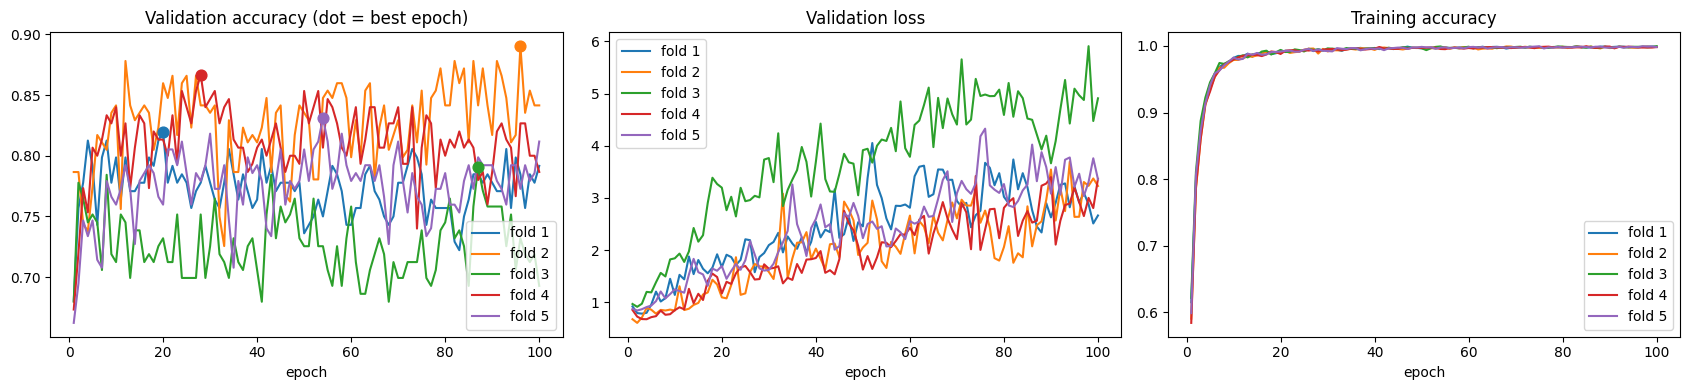

In [10]:
logs = {}
for k in FOLDS:
    with open(OUT / f"fold{k}.json") as f:
        logs[k] = json.load(f)

steps = int(np.ceil(np.mean([len(fold_data[k]["train"]) for k in FOLDS]) * REPEAT / BATCH))
print(f"One epoch is about {steps} optimizer steps, so {EPOCHS} epochs is about {EPOCHS * steps:,} steps per fold")
print("Best validation epoch per fold:", {k: logs[k]["best_epoch"] for k in FOLDS})

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for k in FOLDS:
    h = pd.DataFrame(logs[k]["hist"])
    b = logs[k]["best_epoch"]
    line, = axes[0].plot(h.epoch, h.val_acc, label=f"fold {k}")
    c = line.get_color()
    axes[0].scatter(b, h.val_acc[h.epoch == b], color=c, s=60, zorder=3)
    axes[1].plot(h.epoch, h.val_loss, color=c, label=f"fold {k}")
    axes[2].plot(h.epoch, h.train_acc, color=c, label=f"fold {k}")
titles = ["Validation accuracy (dot = best epoch)", "Validation loss", "Training accuracy"]
for ax, t in zip(axes, titles):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

## 10. Results against the paper

The main row is the final model after 100 epochs, which is the closest match to the paper's setup. The best-validation model is shown underneath for reference. Standard deviations are sample standard deviations over the five folds. The reproduction counts as close enough if our mean accuracy is within 5.39 points of 81.70%, so between 76.31% and 87.09%.

In [11]:
cols = ["acc", "precision", "sensitivity", "f1", "mpox_sens"]

def fold_table(which):
    t = pd.DataFrame([logs[k][which] for k in FOLDS], index=[f"fold {k}" for k in FOLDS])[cols]
    t.loc["mean"] = t.iloc[:len(FOLDS)].mean()
    t.loc["std"] = t.iloc[:len(FOLDS)].std(ddof=1)
    return t

final_t, best_t = fold_table("final"), fold_table("bestval")
print(f"Final model (epoch {EPOCHS}), per fold:")
display(final_t.round(3))

def fmt(t, c):
    m, s = t.loc["mean", c], t.loc["std", c]
    return f"{m:.2f} ± {s:.2f}"

summary = pd.DataFrame({
    "Accuracy (%)": [f"{PAPER['acc'][0]:.2f} ± {PAPER['acc'][1]:.2f}", fmt(final_t, "acc"), fmt(best_t, "acc")],
    "Precision": [f"{PAPER['precision'][0]:.2f} ± {PAPER['precision'][1]:.2f}", fmt(final_t, "precision"), fmt(best_t, "precision")],
    "Sensitivity": [f"{PAPER['sensitivity'][0]:.2f} ± {PAPER['sensitivity'][1]:.2f}", fmt(final_t, "sensitivity"), fmt(best_t, "sensitivity")],
    "F1 score": [f"{PAPER['f1'][0]:.2f} ± {PAPER['f1'][1]:.2f}", fmt(final_t, "f1"), fmt(best_t, "f1")],
}, index=["Ali et al. (2024), Table 2", "Ours, final model", "Ours, best-val model"])
display(summary)

gap = final_t.loc["mean", "acc"] - PAPER["acc"][0]
ok = abs(gap) <= PAPER["acc"][1]
print(f"Accuracy gap (final model): {gap:+.2f} points -> "
      f"{'within' if ok else 'outside'} one standard deviation of the paper")

final_t.to_csv(OUT / "b0_results_final.csv")
best_t.to_csv(OUT / "b0_results_bestval.csv")
summary.to_csv(OUT / "b0_vs_paper.csv")

Final model (epoch 100), per fold:


,acc,precision,sensitivity,f1,mpox_sens
fold 1,79.730,0.841,0.771,0.784,0.815
fold 2,75.610,0.755,0.783,0.755,0.677
fold 3,78.125,0.819,0.763,0.780,0.682
fold 4,76.543,0.783,0.804,0.781,0.593
fold 5,85.714,0.900,0.834,0.856,0.833
mean,79.144,0.820,0.791,0.791,0.720
std,3.994,0.056,0.029,0.038,0.102


,Accuracy (%),Precision,Sensitivity,F1 score
"Ali et al. (2024), Table 2",81.70 ± 5.39,0.83 ± 0.04,0.79 ± 0.06,0.80 ± 0.06
"Ours, final model",79.14 ± 3.99,0.82 ± 0.06,0.79 ± 0.03,0.79 ± 0.04
"Ours, best-val model",81.91 ± 5.26,0.84 ± 0.07,0.79 ± 0.06,0.80 ± 0.06


Accuracy gap (final model): -2.56 points -> within one standard deviation of the paper


## 11. Confusion matrix over all folds

Following the paper, I add up the five test confusion matrices of the final model and normalise each row, so each row shows where the images of one true class ended up. The paper does not say which of its models Fig. 9 shows, so use it as a rough visual reference rather than an exact target.

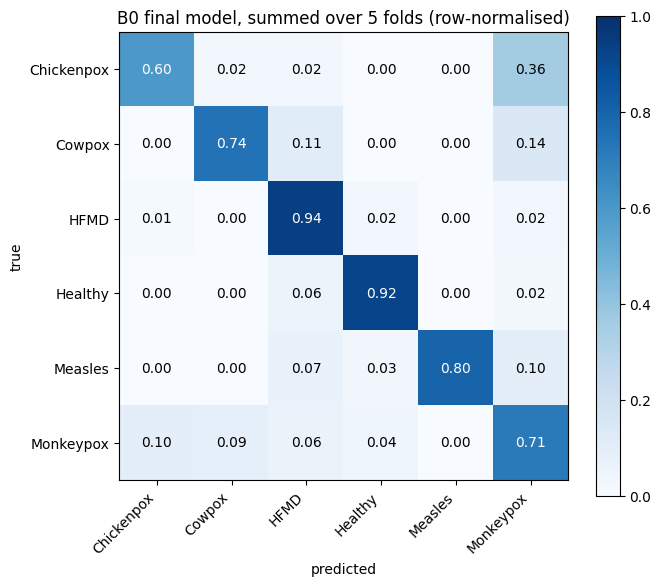

In [12]:
cm = sum(confusion_matrix(logs[k]["labels"], logs[k]["preds_final"], labels=range(NUM_CLASSES)) for k in FOLDS)
cm_norm = cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("B0 final model, summed over 5 folds (row-normalised)")
plt.colorbar(im); plt.tight_layout(); plt.show()

## Notes for the report

Things to state when writing this up: we followed Table 3 of the paper (batch 16, learning rate 0.00001, 100 epochs, Adam, categorical cross-entropy) and reported the final model after epoch 100; one epoch covered 14 augmented passes over the training images to match the size of the paper's augmented training set; augmentation was done on the fly instead of with the shipped augmented folder; only training images were augmented, as in Section 5.1; ReLU was assumed in the hidden layers; and we used PyTorch with Keras-style defaults while the paper used Keras, with torchvision's ImageNet weights instead of Keras's. The shipped dataset contains a byte-identical `_1` copy of every image, which we removed (755 images per fold, as in the paper). The paper does not release its code, so this is a reconstruction from its text, not a copy of the authors' implementation.

If the mean comes out low, the first things I would check are the fold with the lowest accuracy (one bad fold moves the mean a lot with about 75 test images), whether validation loss rises sharply late in training (in which case the best-val row will be noticeably higher), and whether the augmentation is too strong for the smaller classes.